In [27]:
import numpy as np
import pandas as pd
import yfinance as yf
import cvxpy as cp
import dimod
import neal
import matplotlib.pyplot as plt
from datetime import datetime, timedelta
from typing import Dict, List, Tuple
from sklearn.covariance import LedoitWolf
import os
import warnings
import logging
warnings.filterwarnings('ignore')

In [28]:
def download_data(tickers, benchmark, start_date, end_date):
    print(f"Downloading data from {start_date} to {end_date}...")

    data = yf.download(
        tickers,
        start=start_date,
        end=end_date,
        auto_adjust=True,
        progress=False
    )

    if data.empty:
        raise ValueError("No asset data downloaded.")

    prices = data["Close"].copy() if isinstance(data.columns, pd.MultiIndex) else data[["Close"]].copy()

    missing = prices.isnull().sum()
    if missing.any():
        dropped = missing[missing > 0]
        print(f"Missing data warning: {dropped.to_dict()}")
        print(f"Rows before dropna: {len(prices)}")

    prices = prices.dropna()
    print(f"Rows after dropna: {len(prices)}")

    benchmark_data = yf.download(
        benchmark,
        start=start_date,
        end=end_date,
        auto_adjust=True,
        progress=False
    )

    if benchmark_data.empty:
        raise ValueError("No benchmark data downloaded.")

    benchmark_prices = (
        benchmark_data["Close"][benchmark]
        if isinstance(benchmark_data.columns, pd.MultiIndex)
        else benchmark_data["Close"]
    )

    common_dates = prices.index.intersection(benchmark_prices.index)
    prices = prices.loc[common_dates]
    benchmark_prices = benchmark_prices.loc[common_dates]

    print(f"Downloaded {len(prices)} days for {len(prices.columns)} assets")
    return prices, benchmark_prices

In [29]:
def compute_statistics(prices: pd.DataFrame, use_shrinkage: bool = True,
                       use_ewm: bool = False, ewm_halflife: int = 60) -> Tuple[np.ndarray, np.ndarray, pd.DataFrame]:
    returns = prices.pct_change().dropna()

    if use_ewm:
        mu = returns.ewm(halflife=ewm_halflife).mean().iloc[-1].values * 252
        ewm_cov = returns.ewm(halflife=ewm_halflife).cov().iloc[-len(returns.columns):].values * 252
        cov = ewm_cov
    else:
        mu = returns.mean().values * 252
        if use_shrinkage and len(returns) > len(returns.columns):
            lw = LedoitWolf()
            cov = lw.fit(returns).covariance_ * 252
        else:
            cov = returns.cov().values * 252

    print(f"mu:  min={mu.min():.4f}  max={mu.max():.4f}")
    print(f"vol: min={np.sqrt(np.diag(cov)).min():.4f}  max={np.sqrt(np.diag(cov)).max():.4f}")
    print(f"cov: {'EWM' if use_ewm else ('Ledoit-Wolf' if use_shrinkage else 'Sample')}")

    return mu, cov, returns

In [30]:
def build_qubo(mu: np.ndarray, cov: np.ndarray, q: float = 0.5,
               lambda_penalty: float = 10.0, B: int = 5) -> Tuple[np.ndarray, Tuple[float, float]]:
    n = len(mu)

    mu_norm = mu / np.maximum(np.max(np.abs(mu)), 1e-10)
    cov_norm = cov / np.maximum(np.max(np.abs(cov)), 1e-10)

    Q = q * cov_norm.copy()

    for i in range(n):
        Q[i, i] -= mu_norm[i]

    for i in range(n):
        Q[i, i] += lambda_penalty * (1 - 2 * B)
        for j in range(i + 1, n):
            Q[i, j] += 2 * lambda_penalty
            Q[j, i] += 2 * lambda_penalty

    q_scale = np.max(np.abs(Q))
    beta_range = (0.1 / q_scale, 5.0 / q_scale) if q_scale > 1e-10 else (0.1, 5.0)

    print(f"QUBO shape: {Q.shape}")
    print(f"Diagonal range:     [{Q.diagonal().min():.4f}, {Q.diagonal().max():.4f}]")
    print(f"Off-diagonal range: [{Q[np.triu_indices(n, k=1)].min():.4f}, {Q[np.triu_indices(n, k=1)].max():.4f}]")
    print(f"beta_range: [{beta_range[0]:.4f}, {beta_range[1]:.4f}]")

    return Q, beta_range

In [31]:
def solve_qubo_sa(Q: np.ndarray, num_reads: int = 1000, B: int = 5,
                  seed: int = 42, beta_range: Tuple[float, float] = (0.1, 5.0),
                  n_seeds: int = 5, warm_start: np.ndarray = None) -> Tuple[np.ndarray, float]:
    n = Q.shape[0]

    qubo_dict = {
        (i, j): Q[i, j]
        for i in range(n)
        for j in range(i, n)
        if Q[i, j] != 0
    }

    bqm = dimod.BinaryQuadraticModel.from_qubo(qubo_dict)
    sampler = neal.SimulatedAnnealingSampler()

    all_solutions = []

    for s in range(n_seeds):
        kwargs = dict(
            num_reads=num_reads,
            seed=seed + s,
            beta_range=list(beta_range),
            num_sweeps=1000
        )

        if warm_start is not None:
            init_sample = {i: int(warm_start[i]) for i in range(n)}
            kwargs['initial_states'] = [init_sample]

        sampleset = sampler.sample(bqm, **kwargs)
        best = sampleset.first
        sol = np.array([best.sample.get(i, 0) for i in range(n)])
        all_solutions.append(sol)

    vote = np.mean(all_solutions, axis=0)
    solution = (vote >= 0.5).astype(int)

    num_selected = int(solution.sum())
    print(f"Multi-seed vote ({n_seeds} seeds), assets selected (raw): {num_selected} (target: {B})")

    if num_selected != B:
        print(f"Cardinality violation: {num_selected} != {B}, enforcing...")
        scores = -np.diag(Q)
        solution = enforce_cardinality(solution, scores, B)
        print(f"Assets selected (after enforcement): {int(solution.sum())}")

    print(f"Selected indices: {np.where(solution == 1)[0].tolist()}")

    final_energy = solution @ Q @ solution
    return solution, float(final_energy)

In [32]:
def optimize_weights(mu: np.ndarray, cov: np.ndarray, selected: np.ndarray) -> np.ndarray:
    n = len(mu)
    indices = np.where(selected == 1)[0]
    k = len(indices)

    if k == 0:
        print("No assets selected, returning zeros")
        return np.zeros(n)

    mu_s = mu[indices]
    cov_s = cov[np.ix_(indices, indices)]

    print(f"Optimizing weights for {k} assets...")

    w = cp.Variable(k)
    objective = cp.Minimize(cp.quad_form(w, cov_s))
    constraints = [mu_s @ w == 1, w >= 0]
    problem = cp.Problem(objective, constraints)

    try:
        problem.solve(solver=cp.ECOS, verbose=False)

        if problem.status == 'optimal':
            weights_selected = w.value / np.sum(w.value)
            weights_full = np.zeros(n)
            weights_full[indices] = weights_selected
            print("Optimization successful")
            return weights_full
        else:
            print(f"Solver status: {problem.status}, using equal weights")

    except Exception as e:
        print(f"Optimization error: {e}, using equal weights")

    weights_full = np.zeros(n)
    weights_full[indices] = 1.0 / k
    return weights_full

In [33]:
def compute_metrics(weights: np.ndarray, mu: np.ndarray, cov: np.ndarray,
                    risk_free_rate: float = 0.0) -> Dict[str, float]:
    expected_return = np.dot(mu, weights)

    portfolio_variance = np.dot(weights, np.dot(cov, weights))
    portfolio_volatility = np.sqrt(portfolio_variance)

    sharpe_ratio = (
        (expected_return - risk_free_rate) / portfolio_volatility
        if portfolio_volatility > 0 else 0
    )

    individual_vols = np.sqrt(np.diag(cov))
    weighted_avg_vol = np.dot(weights, individual_vols)
    diversification_ratio = weighted_avg_vol / portfolio_volatility if portfolio_volatility > 0 else 0

    metrics = {
        'expected_return': expected_return,
        'volatility': portfolio_volatility,
        'sharpe_ratio': sharpe_ratio,
        'diversification_ratio': diversification_ratio
    }

    print(f"Expected Return:       {expected_return*100:>8.2f}%")
    print(f"Volatility:            {portfolio_volatility*100:>8.2f}%")
    print(f"Sharpe Ratio:          {sharpe_ratio:>8.4f}")
    print(f"Diversification Ratio: {diversification_ratio:>8.4f}")

    return metrics

In [34]:
def backtest(prices: pd.DataFrame, weights: np.ndarray,
             initial_capital: float, transaction_cost: float = 0.002) -> pd.Series:
    initial_prices = prices.iloc[0].values

    shares = (weights * initial_capital) / initial_prices
    shares = np.nan_to_num(shares, nan=0.0, posinf=0.0)

    invested = np.sum(shares * initial_prices)
    tc = transaction_cost * np.sum(weights * initial_capital)
    cash = initial_capital - invested - tc

    print(f"Initial capital:  {initial_capital:,.0f}")
    print(f"Amount invested:  {invested:,.0f}")
    print(f"Transaction cost: {tc:,.0f}")
    print(f"Remaining cash:   {cash:,.0f}")

    portfolio_values = (prices.values * shares).sum(axis=1) + cash
    return pd.Series(portfolio_values, index=prices.index)

In [35]:
def compute_max_drawdown(portfolio_values: pd.Series) -> float:
    cummax = portfolio_values.cummax()
    drawdown = (portfolio_values - cummax) / cummax
    return drawdown.min()


def backtest_benchmark(prices: pd.Series, initial_capital: float = 1600000) -> pd.Series:
    units = initial_capital / prices.iloc[0]
    return prices * units


def compute_rolling_sharpe(portfolio_values: pd.Series, window: int = 90,
                            risk_free_rate: float = 0.0) -> pd.Series:
    daily_returns = portfolio_values.pct_change().dropna()
    excess = daily_returns - risk_free_rate / 252
    rolling_sharpe = (
        excess.rolling(window).mean() /
        excess.rolling(window).std()
    ) * np.sqrt(252)
    return rolling_sharpe


def compute_annualized_return(portfolio_values: pd.Series) -> float:
    total_days = (portfolio_values.index[-1] - portfolio_values.index[0]).days
    total_return = portfolio_values.iloc[-1] / portfolio_values.iloc[0]
    return total_return ** (365.0 / total_days) - 1

In [36]:
def rebalance_portfolio(prices: pd.DataFrame, tickers: List[str],
                        initial_capital: float = 1600000,
                        q: float = 0.5, B: int = 5,
                        rebalance_months: int = 3, lookback_days: int = 252,
                        transaction_cost: float = 0.002) -> Tuple[pd.Series, List]:
    rebalance_days = rebalance_months * 21
    portfolio_values = []
    dates = []
    rebalance_info = []
    current_capital = initial_capital
    shares = np.zeros(len(prices.columns))
    prev_solution = None

    print("QUARTERLY REBALANCING BACKTEST")

    for i in range(0, len(prices), rebalance_days):
        rebalance_date = prices.index[i]
        print(f"\nRebalancing on {rebalance_date.date()}")

        lookback_start = 0 if i == 0 else max(0, i - lookback_days)
        lookback_end = i

        if lookback_end <= lookback_start:
            print("Insufficient data, skipping...")
            continue

        returns_window = prices.iloc[lookback_start:lookback_end].pct_change().dropna()
        mu = returns_window.mean().values * 252
        cov = returns_window.cov().values * 252

        lambda_penalty = compute_lambda(mu, cov, q, B, alpha=5.0)
        Q, beta_range = build_qubo(mu, cov, q, lambda_penalty, B)
        energy_check(Q, B)

        selected, energy = solve_qubo_sa(
            Q, num_reads=1000, B=B, seed=42,
            beta_range=beta_range,
            warm_start=prev_solution
        )
        prev_solution = selected.copy()

        weights = optimize_weights(mu, cov, selected)

        current_prices = prices.iloc[i].values
        new_shares = (weights * current_capital) / current_prices
        new_shares = np.nan_to_num(new_shares, nan=0.0, posinf=0.0)

        turnover = np.sum(np.abs(new_shares * current_prices - shares * current_prices))
        tc = transaction_cost * turnover
        current_capital -= tc
        shares = new_shares

        selected_tickers = [tickers[j] for j in range(len(tickers)) if selected[j] == 1]
        rebalance_info.append({
            'date': rebalance_date,
            'selected': selected_tickers,
            'weights': weights[selected == 1],
            'capital': current_capital,
            'lambda': lambda_penalty,
            'turnover': turnover,
            'transaction_cost': tc
        })

        print(f"Selected:         {selected_tickers}")
        print(f"Turnover:         {turnover:,.0f}")
        print(f"Transaction cost: {tc:,.0f}")
        print(f"Capital:          {current_capital:,.0f}")

        next_rebalance = min(i + rebalance_days, len(prices))

        for j in range(i, next_rebalance):
            portfolio_values.append(np.dot(shares, prices.iloc[j].values))
            dates.append(prices.index[j])

        current_capital = portfolio_values[-1]

    return pd.Series(portfolio_values, index=dates), rebalance_info

In [37]:
def plot_results(portfolio_values: pd.Series, benchmark_values: pd.Series,
                 portfolio_rebalanced: pd.Series, tickers: List[str],
                 weights: np.ndarray, rebalance_info: List):
    fig = plt.figure(figsize=(20, 16))

    ax1 = plt.subplot(3, 2, 1)
    portfolio_values.plot(ax=ax1, label='Strategy (No Rebalancing)', linewidth=2.5, color='#2E86AB')
    benchmark_values.plot(ax=ax1, label='Benchmark (NIFTY 50)', linewidth=2.5, color='#A23B72', alpha=0.8)
    ax1.set_title('Portfolio Performance vs Benchmark', fontsize=14, fontweight='bold')
    ax1.set_ylabel('Value (INR)')
    ax1.legend(fontsize=10)
    ax1.grid(True, alpha=0.3, linestyle='--')
    ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{x/1e6:.2f}M'))

    ax2 = plt.subplot(3, 2, 2)
    portfolio_ret = (portfolio_values / portfolio_values.iloc[0] - 1) * 100
    benchmark_ret = (benchmark_values / benchmark_values.iloc[0] - 1) * 100
    portfolio_ret.plot(ax=ax2, label='Strategy', linewidth=2.5, color='#2E86AB')
    benchmark_ret.plot(ax=ax2, label='Benchmark', linewidth=2.5, color='#A23B72', alpha=0.8)
    ax2.set_title('Cumulative Returns', fontsize=14, fontweight='bold')
    ax2.set_ylabel('Return (%)')
    ax2.legend(fontsize=10)
    ax2.grid(True, alpha=0.3, linestyle='--')
    ax2.axhline(y=0, color='black', linewidth=0.8, alpha=0.5)

    ax3 = plt.subplot(3, 2, 3)
    portfolio_values.plot(ax=ax3, label='Without Rebalancing', linewidth=2.5, color='#2E86AB', alpha=0.7)
    portfolio_rebalanced.plot(ax=ax3, label='With Quarterly Rebalancing', linewidth=2.5, color='#F18F01')
    benchmark_values.plot(ax=ax3, label='Benchmark', linewidth=2, color='#A23B72', alpha=0.5, linestyle='--')
    ax3.set_title('Impact of Quarterly Rebalancing', fontsize=14, fontweight='bold')
    ax3.set_ylabel('Value (INR)')
    ax3.legend(fontsize=10)
    ax3.grid(True, alpha=0.3, linestyle='--')
    ax3.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{x/1e6:.2f}M'))

    ax4 = plt.subplot(3, 2, 4)
    selected_indices = np.where(weights > 0)[0]
    if len(selected_indices) > 0:
        selected_weights = weights[selected_indices]
        selected_tickers = [tickers[i].replace('.NS', '') for i in selected_indices]
        colors = ['#2E86AB', '#A23B72', '#F18F01', '#C73E1D', '#6A994E']
        bars = ax4.barh(selected_tickers, selected_weights, color=colors, edgecolor='black', linewidth=1.5)
        ax4.set_title('Optimal Portfolio Weights', fontsize=14, fontweight='bold')
        ax4.set_xlabel('Weight')
        ax4.grid(True, alpha=0.3, axis='x', linestyle='--')
        for bar in bars:
            width = bar.get_width()
            ax4.text(width, bar.get_y() + bar.get_height() / 2,
                     f' {width:.3f} ({width*100:.1f}%)',
                     ha='left', va='center', fontsize=10, fontweight='bold')

    ax5 = plt.subplot(3, 2, 5)
    rolling_sharpe = compute_rolling_sharpe(portfolio_rebalanced, window=90)
    rolling_sharpe.plot(ax=ax5, linewidth=2, color='#6A994E')
    ax5.axhline(y=0, color='black', linewidth=0.8, alpha=0.5)
    ax5.set_title('Rolling 90-day Sharpe (Rebalanced)', fontsize=14, fontweight='bold')
    ax5.set_ylabel('Sharpe Ratio')
    ax5.grid(True, alpha=0.3, linestyle='--')

    ax6 = plt.subplot(3, 2, 6)
    if rebalance_info:
        all_tickers_clean = [t.replace('.NS', '') for t in tickers]
        n_periods = len(rebalance_info)
        n_assets = len(tickers)
        held = np.zeros((n_assets, n_periods))

        for col, info in enumerate(rebalance_info):
            for t in info['selected']:
                t_clean = t.replace('.NS', '')
                if t_clean in all_tickers_clean:
                    row = all_tickers_clean.index(t_clean)
                    held[row, col] = 1

        ax6.imshow(held, aspect='auto', cmap='Blues', interpolation='nearest')
        ax6.set_yticks(range(n_assets))
        ax6.set_yticklabels(all_tickers_clean, fontsize=8)
        ax6.set_xticks(range(n_periods))
        ax6.set_xticklabels(
            [str(info['date'].date()) for info in rebalance_info],
            rotation=45, ha='right', fontsize=7
        )
        ax6.set_title('Asset Holdings per Rebalance Period', fontsize=14, fontweight='bold')

    plt.tight_layout()
    return fig


def print_final_report(portfolio_initial, portfolio_final,
                       benchmark_initial, benchmark_final,
                       portfolio_rebalanced_final,
                       portfolio_values, benchmark_values,
                       portfolio_rebalanced,
                       metrics, tickers, weights, rebalance_info):
    print(f"\n{'='*80}")
    print("FINAL PERFORMANCE REPORT")
    print(f"{'='*80}\n")

    print(f"Initial capital: {portfolio_initial:,.0f}\n")

    portfolio_return = (portfolio_final - portfolio_initial) / portfolio_initial * 100
    ann_return_static = compute_annualized_return(portfolio_values) * 100
    max_dd_strategy = compute_max_drawdown(portfolio_values)
    print("Strategy (Buy & Hold)")
    print(f"  Final Value:        {portfolio_final:,.0f}")
    print(f"  Total Return:       {portfolio_return:>+8.2f}%")
    print(f"  Annualized Return:  {ann_return_static:>+8.2f}%")
    print(f"  Max Drawdown:       {max_dd_strategy:>8.2%}\n")

    rebalanced_return = (portfolio_rebalanced_final - portfolio_initial) / portfolio_initial * 100
    ann_return_dynamic = compute_annualized_return(portfolio_rebalanced) * 100
    max_dd_rebalanced = compute_max_drawdown(portfolio_rebalanced)
    total_tc = sum(r['transaction_cost'] for r in rebalance_info)
    print("Strategy (Quarterly Rebalancing)")
    print(f"  Final Value:        {portfolio_rebalanced_final:,.0f}")
    print(f"  Total Return:       {rebalanced_return:>+8.2f}%")
    print(f"  Annualized Return:  {ann_return_dynamic:>+8.2f}%")
    print(f"  Max Drawdown:       {max_dd_rebalanced:>8.2%}")
    print(f"  Total Trans. Costs: {total_tc:,.0f}\n")

    benchmark_return = (benchmark_final - benchmark_initial) / benchmark_initial * 100
    ann_return_bench = compute_annualized_return(benchmark_values) * 100
    max_dd_benchmark = compute_max_drawdown(benchmark_values)
    print("Benchmark (NIFTY 50)")
    print(f"  Final Value:        {benchmark_final:,.0f}")
    print(f"  Total Return:       {benchmark_return:>+8.2f}%")
    print(f"  Annualized Return:  {ann_return_bench:>+8.2f}%")
    print(f"  Max Drawdown:       {max_dd_benchmark:>8.2%}\n")

    print("Outperformance")
    print(f"  Static vs Benchmark:   {portfolio_return - benchmark_return:>+8.2f}%")
    print(f"  Dynamic vs Benchmark:  {rebalanced_return - benchmark_return:>+8.2f}%")
    print(f"  Rebalancing Benefit:   {rebalanced_return - portfolio_return:>+8.2f}%\n")

    print("Portfolio Characteristics (initial)")
    print(f"  Expected Return: {metrics['expected_return']*100:>8.2f}%")
    print(f"  Volatility:      {metrics['volatility']*100:>8.2f}%")
    print(f"  Sharpe Ratio:    {metrics['sharpe_ratio']:>8.4f}")
    print(f"  Div Ratio:       {metrics['diversification_ratio']:>8.4f}\n")

    print("Selected Assets (initial)")
    for idx in np.where(weights > 0)[0]:
        print(f"  {tickers[idx]:<15} {weights[idx]:.4f} ({weights[idx]*100:.1f}%)")

    print(f"\n{'='*80}")

In [38]:
def setup_logger(log_path: str = 'logs/run.log') -> logging.Logger:
    os.makedirs(os.path.dirname(log_path), exist_ok=True)
    logger = logging.getLogger('qubo')
    logger.setLevel(logging.INFO)
    if not logger.handlers:
        fh = logging.FileHandler(log_path)
        fh.setFormatter(logging.Formatter('%(asctime)s  %(message)s'))
        logger.addHandler(fh)
        sh = logging.StreamHandler()
        sh.setFormatter(logging.Formatter('%(message)s'))
        logger.addHandler(sh)
    return logger


def compute_lambda(mu: np.ndarray, cov: np.ndarray, q: float, B: int,
                   alpha: float = 5.0) -> float:
    mu_scale = np.max(np.abs(mu))
    lambda_penalty = max(
        alpha * mu_scale * B,
        2 * np.max(np.abs(cov))
    )
    print(f"Lambda:  max|mu|={mu_scale:.4f}  max|cov|={np.max(np.abs(cov)):.4f}  B={B}  lambda={lambda_penalty:.4f}")
    return lambda_penalty


def enforce_cardinality(x: np.ndarray, scores: np.ndarray, B: int) -> np.ndarray:
    x_enforced = x.copy()
    selected_idx = np.where(x_enforced == 1)[0]
    unselected_idx = np.where(x_enforced == 0)[0]
    num_selected = len(selected_idx)

    if num_selected > B:
        worst = np.argsort(scores[selected_idx])[:num_selected - B]
        x_enforced[selected_idx[worst]] = 0
    elif num_selected < B:
        if len(unselected_idx) > 0:
            best = np.argsort(scores[unselected_idx])[-(B - num_selected):]
            x_enforced[unselected_idx[best]] = 1

    return x_enforced


def energy_check(Q: np.ndarray, B: int):
    n = Q.shape[0]
    x_B = np.zeros(n); x_B[:B] = 1
    x_more = np.zeros(n); x_more[:B + 2] = 1
    e_B = x_B @ Q @ x_B
    e_more = x_more @ Q @ x_more
    print(f"Energy check  E(B={B}): {e_B:.4f}  E(B+2={B+2}): {e_more:.4f}")
    if e_B >= e_more:
        print("  WARNING: E(B) >= E(B+2) - lambda too small")
    return e_B, e_more

In [39]:
def run_pipeline(
    tickers: List[str],
    benchmark: str,
    start_date: datetime,
    end_date: datetime,
    initial_capital: float,
    q: float,
    B: int
):
    logger = setup_logger()
    os.makedirs('plots', exist_ok=True)

    logger.info("STEP 1: DATA COLLECTION")
    prices, benchmark_prices = download_data(tickers, benchmark, start_date, end_date)

    train_size = int(0.67 * len(prices))
    train_prices = prices.iloc[:train_size]
    test_prices = prices.iloc[train_size:]
    test_benchmark = benchmark_prices.iloc[train_size:]

    logger.info(f"Train: {train_prices.index[0].date()} to {train_prices.index[-1].date()} ({len(train_prices)} days)")
    logger.info(f"Test:  {test_prices.index[0].date()} to {test_prices.index[-1].date()} ({len(test_prices)} days)")

    mu_train, cov_train, _ = compute_statistics(train_prices)

    logger.info("STEP 2-5: PORTFOLIO CONSTRUCTION")
    lambda_penalty = compute_lambda(mu_train, cov_train, q, B, alpha=5.0)
    Q, beta_range = build_qubo(mu_train, cov_train, q, lambda_penalty, B)
    energy_check(Q, B)
    selected, energy = solve_qubo_sa(Q, num_reads=1000, B=B, seed=42, beta_range=beta_range)
    weights = optimize_weights(mu_train, cov_train, selected)
    metrics = compute_metrics(weights, mu_train, cov_train, risk_free_rate=0.0)

    logger.info("STEP 6: BACKTEST")
    portfolio_values = backtest(test_prices, weights, initial_capital)
    benchmark_values = backtest_benchmark(test_benchmark, initial_capital)
    logger.info(f"Period: {test_prices.index[0].date()} to {test_prices.index[-1].date()}")
    logger.info(f"Final:  {portfolio_values.iloc[-1]:,.0f}")

    logger.info("STEP 7: QUARTERLY REBALANCING")
    portfolio_rebalanced, rebalance_info = rebalance_portfolio(
        test_prices, tickers, initial_capital,
        q, B,
        rebalance_months=3, lookback_days=252
    )

    logger.info("STEP 8: REPORTING")
    fig = plot_results(
        portfolio_values, benchmark_values, portfolio_rebalanced,
        tickers, weights, rebalance_info
    )
    plt.savefig('plots/portfolio_results.png', dpi=300, bbox_inches='tight')
    logger.info("Saved: plots/portfolio_results.png")

    print_final_report(
        initial_capital, portfolio_values.iloc[-1].item(),
        initial_capital, benchmark_values.iloc[-1].item(),
        portfolio_rebalanced.iloc[-1].item(),
        portfolio_values, benchmark_values, portfolio_rebalanced,
        metrics, tickers, weights, rebalance_info
    )

In [42]:
def main():
    TICKERS = [
        'TCS.NS', 'INFY.NS', 'HDFCBANK.NS', 'ICICIBANK.NS', 'SBIN.NS',
        'HINDUNILVR.NS', 'ITC.NS', 'LT.NS', 'RELIANCE.NS', 'BHARTIARTL.NS'
    ]
    BENCHMARK       = '^NSEI'
    START_DATE      = datetime(2023, 1, 1)
    END_DATE        = datetime(2026, 1, 1)
    INITIAL_CAPITAL = 1600000
    Q_RISK_AVERSION = 0.5
    B_ASSETS        = 5

    run_pipeline(
        tickers=TICKERS,
        benchmark=BENCHMARK,
        start_date=START_DATE,
        end_date=END_DATE,
        initial_capital=INITIAL_CAPITAL,
        q=Q_RISK_AVERSION,
        B=B_ASSETS
    )

STEP 1: DATA COLLECTION
Train: 2023-01-02 to 2025-01-06 (495 days)


Rows after dropna: 740
Downloaded 740 days for 10 assets


Test:  2025-01-07 to 2025-12-31 (245 days)
STEP 2-5: PORTFOLIO CONSTRUCTION


mu:  min=-0.0019  max=0.3675
vol: min=0.1859  max=0.2509
cov: Ledoit-Wolf
Lambda:  max|mu|=0.3675  max|cov|=0.0630  B=5  lambda=9.1865
QUBO shape: (10, 10)
Diagonal range:     [-83.3469, -82.3956]
Off-diagonal range: [18.3789, 18.5970]
beta_range: [0.0012, 0.0600]
Energy check  E(B=5): -45.2892  E(B+2=7): 194.3801


STEP 6: BACKTEST
Period: 2025-01-07 to 2025-12-31
Final:  1,815,725
STEP 7: QUARTERLY REBALANCING


Multi-seed vote (5 seeds), assets selected (raw): 5 (target: 5)
Selected indices: [0, 3, 5, 6, 9]
Optimizing weights for 5 assets...
Optimization successful
Expected Return:          29.06%
Volatility:               13.44%
Sharpe Ratio:            2.1630
Diversification Ratio:   1.5251
Initial capital:  1,600,000
Amount invested:  1,600,000
Transaction cost: 3,200
Remaining cash:   -3,200
QUARTERLY REBALANCING BACKTEST

Rebalancing on 2025-01-07
Insufficient data, skipping...

Rebalancing on 2025-04-08
Lambda:  max|mu|=1.2717  max|cov|=0.0886  B=5  lambda=31.7916
QUBO shape: (10, 10)
Diagonal range:     [-286.0098, -284.6588]
Off-diagonal range: [63.5690, 63.8425]
beta_range: [0.0003, 0.0175]
Energy check  E(B=5): -155.4765  E(B+2=7): 673.8562
Multi-seed vote (5 seeds), assets selected (raw): 5 (target: 5)
Selected indices: [0, 1, 2, 3, 5]
Optimizing weights for 5 assets...
Optimization successful
Selected:         ['TCS.NS', 'INFY.NS', 'HDFCBANK.NS', 'ICICIBANK.NS', 'HINDUNILVR.NS']
T

STEP 8: REPORTING


Multi-seed vote (5 seeds), assets selected (raw): 5 (target: 5)
Selected indices: [0, 1, 2, 7, 8]
Optimizing weights for 5 assets...
Optimization successful
Selected:         ['TCS.NS', 'INFY.NS', 'HDFCBANK.NS', 'LT.NS', 'RELIANCE.NS']
Turnover:         1,062,204
Transaction cost: 2,124
Capital:          1,807,985


Saved: plots/portfolio_results.png



FINAL PERFORMANCE REPORT

Initial capital: 1,600,000

Strategy (Buy & Hold)
  Final Value:        1,815,725
  Total Return:         +13.48%
  Annualized Return:    +14.00%
  Max Drawdown:         -8.30%

Strategy (Quarterly Rebalancing)
  Final Value:        1,894,444
  Total Return:         +18.40%
  Annualized Return:    +25.98%
  Max Drawdown:         -5.64%
  Total Trans. Costs: 6,813

Benchmark (NIFTY 50)
  Final Value:        1,763,436
  Total Return:         +10.21%
  Annualized Return:    +10.42%
  Max Drawdown:         -6.98%

Outperformance
  Static vs Benchmark:      +3.27%
  Dynamic vs Benchmark:     +8.19%
  Rebalancing Benefit:      +4.92%

Portfolio Characteristics (initial)
  Expected Return:    29.06%
  Volatility:         13.44%
  Sharpe Ratio:      2.1630
  Div Ratio:         1.5251

Selected Assets (initial)
  TCS.NS          0.4090 (40.9%)
  ICICIBANK.NS    0.0854 (8.5%)
  HINDUNILVR.NS   0.2198 (22.0%)
  ITC.NS          0.1869 (18.7%)
  BHARTIARTL.NS   0.0990 (9.

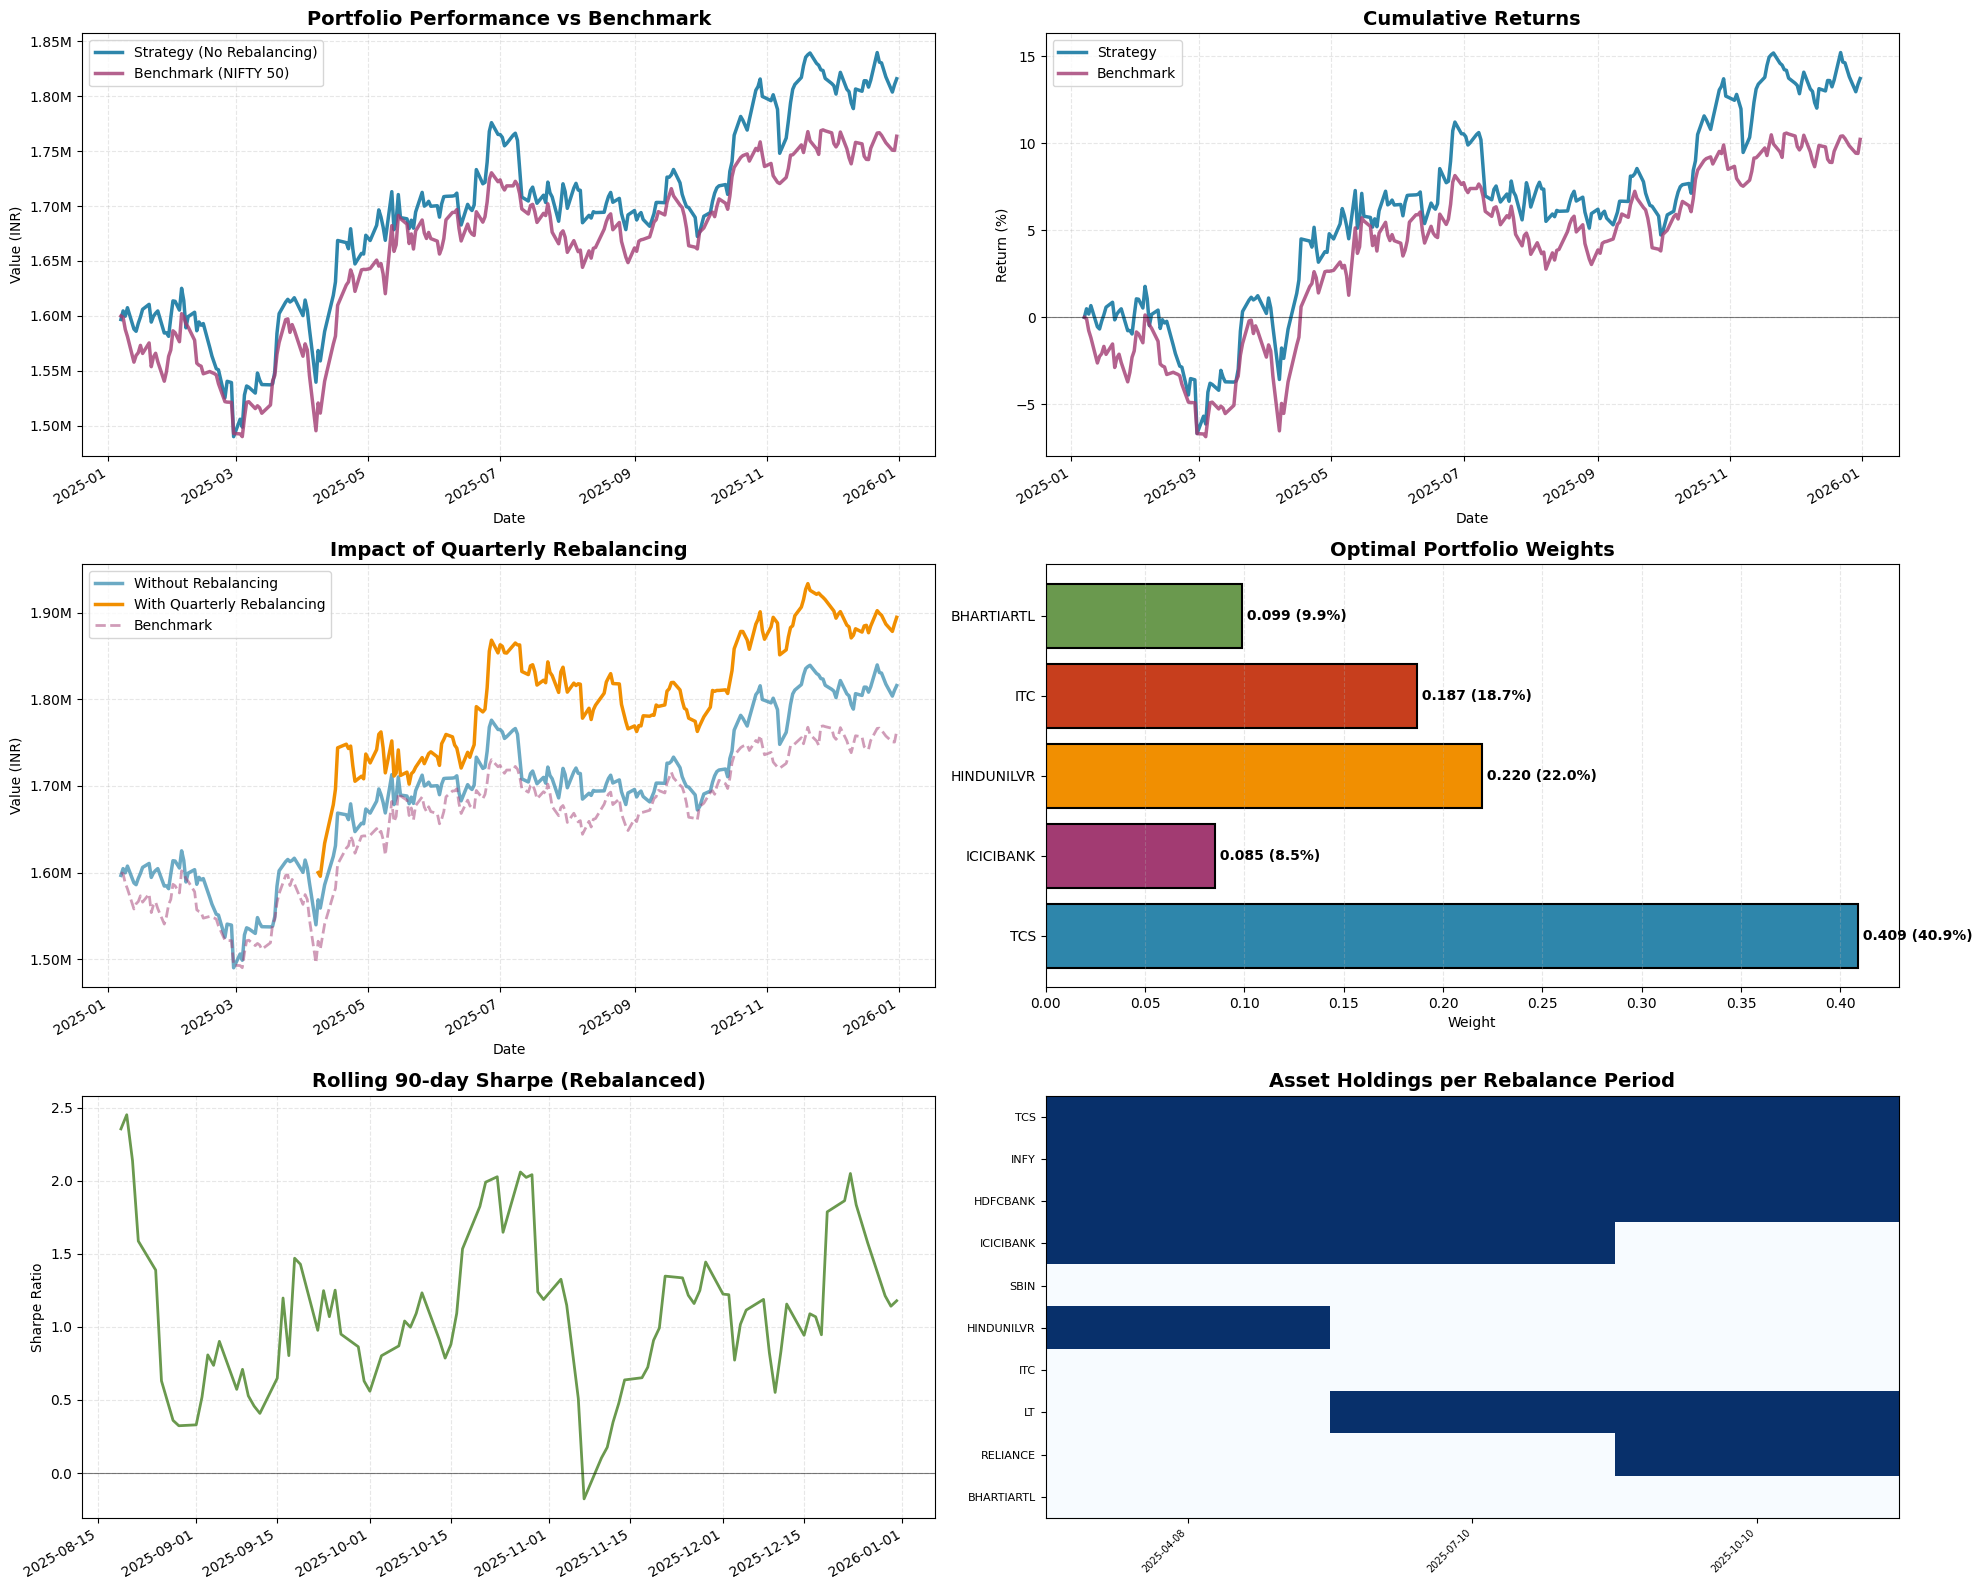

In [43]:
if __name__ == "__main__":
    main()